# Deep Learning PR 2 — Adult Income Prediction with ANN
**Red & White Skill Education · Deep Learning · PR 2**

In this notebook I predict whether a person earns more than $50K a year using the Adult Income (Census) dataset.
I build one reusable function `build_ann()` and then change **one thing at a time** (activation, weight initialisation, loss function, Batch Normalization, optimizer) to see what each one changes.

**Notes**
- Target: `0 = <=50K`, `1 = >50K`. The classes are imbalanced (about 75% / 25%), so I look at **Precision, Recall and F1 of class 1 (>50K)** and not only accuracy.
- Training runs use `verbose=0` to keep the notebook short.
- The numbers in the observation cells are from my run. They can change a little on another computer or TensorFlow version.
- Validation uses `validation_split=0.1`, which is about 3,300 rows, so tiny differences between models are just noise.

## Task 1: Data Loading, Cleaning & Exploratory Data Analysis
**Objective:** load and clean the data, explore it, encode the categorical columns, scale the numeric columns and split into train and test sets.

**Expected output:** clean dataframe, class balance plot, 4 EDA plots, scaled train/test arrays.

### 1.1 - Load and inspect the dataset

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             precision_score, recall_score, f1_score, roc_auc_score, roc_curve)

sns.set_style("whitegrid")
os.makedirs("plots", exist_ok=True)
RED, CHARCOAL = "#CC0000", "#2C2C2C"

I0000 00:00:1793273278.635083    1200 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793273280.019320    1200 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
df = pd.read_csv("adult.csv")

# remove extra spaces from all text columns
for col in df.select_dtypes("object"):
    df[col] = df[col].str.strip()

print("df.shape:", df.shape)
print()
print(df.dtypes)
df.head()

df.shape: (48842, 15)

age                int64
workclass            str
fnlwgt             int64
education            str
educational-num    int64
marital-status       str
occupation           str
relationship         str
race                 str
gender               str
capital-gain       int64
capital-loss       int64
hours-per-week     int64
native-country       str
income               str
dtype: object


/tmp/ipykernel_1200/2336642773.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes("object"):


,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K


### 1.2 - Handle missing values

In [3]:
df = df.replace("?", np.nan)
print(df.isnull().sum()[df.isnull().sum() > 0])

rows_before = len(df)
df = df.dropna()
print("\nRows before:", rows_before, "| after dropna:", len(df), "| removed:", rows_before - len(df))

workclass         2799
occupation        2809
native-country     857
dtype: int64

Rows before: 48842 | after dropna: 45222 | removed: 3620


**Why drop and not impute?** The missing values are in categorical columns (`workclass`, `occupation`, `native-country`) that have many categories. Mode imputation would put every missing person into the most common category (for example `Private`), which would make that category look bigger than it really is. Only about 7% of the rows have a missing value, so dropping them is safe.

### 1.3 - Drop redundant columns

In [4]:
# fnlwgt is a census sampling weight, education (text) is the same as educational-num
df = df.drop(columns=["fnlwgt", "education"])
print("df.shape:", df.shape)

df.shape: (45222, 13)


### 1.4 - Encode the target

income
0    34014
1    11208
Name: count, dtype: int64
income
0    0.752
1    0.248
Name: proportion, dtype: float64


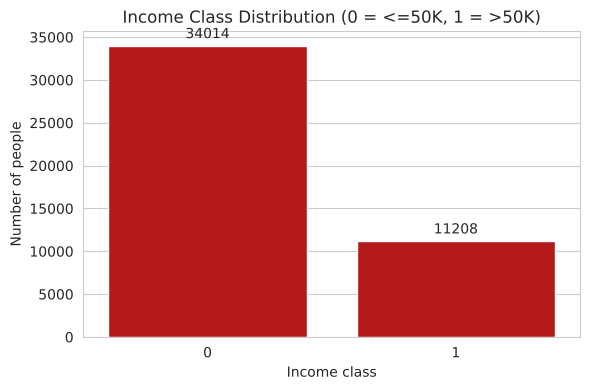

In [5]:
df["income"] = (df["income"] == ">50K").astype(int)
print(df["income"].value_counts())
print(df["income"].value_counts(normalize=True).round(3))

plt.figure(figsize=(6, 4))
ax = sns.countplot(x="income", data=df, color=RED)
ax.set_title("Income Class Distribution (0 = <=50K, 1 = >50K)")
ax.set_xlabel("Income class")
ax.set_ylabel("Number of people")
for c in ax.containers:
    ax.bar_label(c, fmt="%d", padding=3)
plt.tight_layout()
plt.savefig("plots/eda_class_balance.png", dpi=120)
plt.show()

### Observation: class imbalance


After cleaning, 34,014 people (75.2%) earn <=50K and 11,208 (24.8%) earn >50K, about 3 : 1. This is why accuracy alone is misleading: a model that always says "<=50K" would already get about 75% accuracy and would never find a single high earner. So from now on I track **Precision, Recall and F1 of class 1 (>50K)** next to accuracy.

Note: the file has 45,222 rows after dropping missing values (3,620 rows removed), a bit fewer than the ~46,443 written in the brief, because this CSV has more `?` values.


### 1.5 - Exploratory visualisations

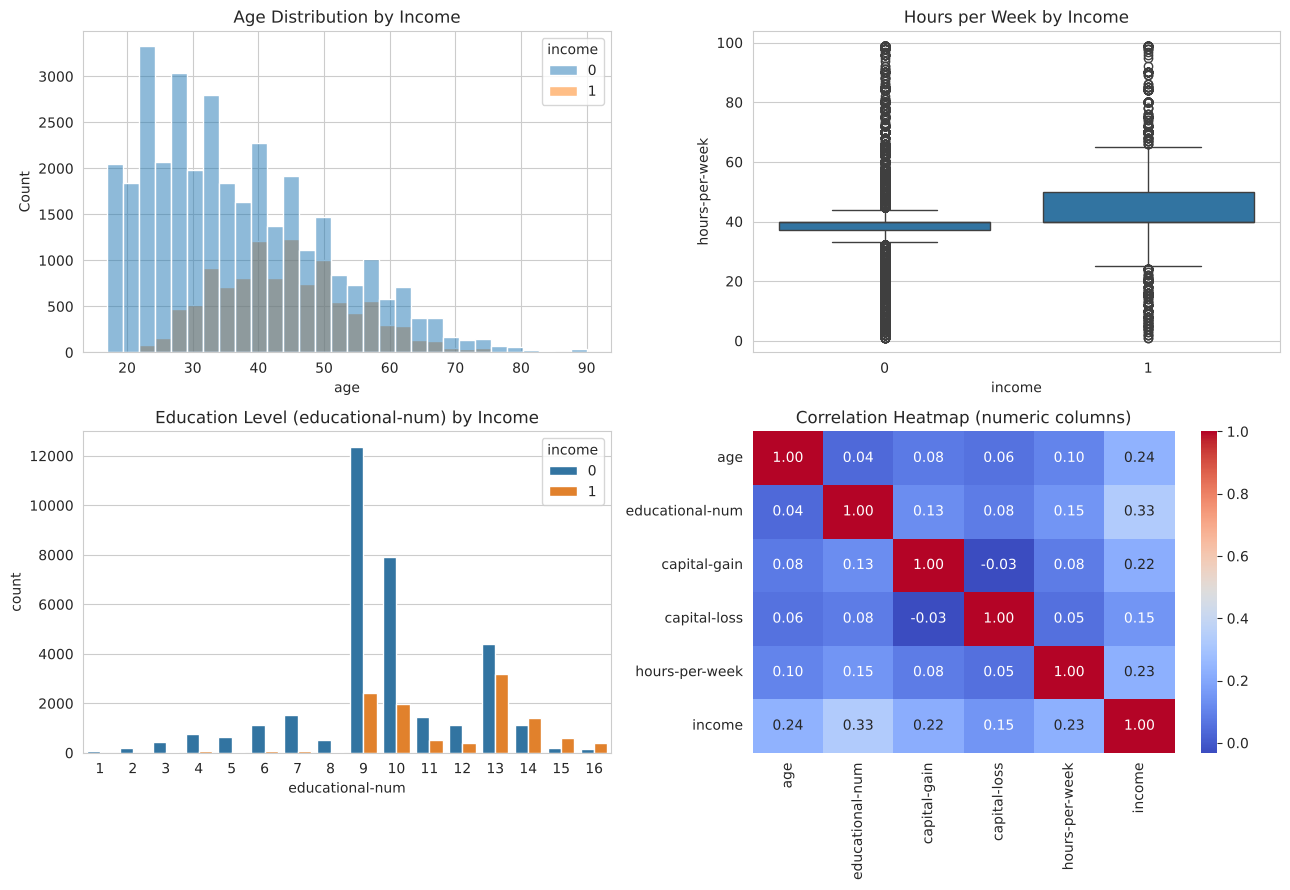

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

sns.histplot(data=df, x="age", hue="income", bins=30, ax=axes[0, 0])
axes[0, 0].set_title("Age Distribution by Income")

sns.boxplot(data=df, x="income", y="hours-per-week", ax=axes[0, 1])
axes[0, 1].set_title("Hours per Week by Income")

sns.countplot(data=df, x="educational-num", hue="income", ax=axes[1, 0])
axes[1, 0].set_title("Education Level (educational-num) by Income")

num_cols = ["age", "educational-num", "capital-gain", "capital-loss", "hours-per-week", "income"]
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1, 1])
axes[1, 1].set_title("Correlation Heatmap (numeric columns)")

plt.tight_layout()
plt.show()

### Observation: what the plots show


- **Age:** people earning >50K are older (median 43 vs 34).
- **Hours per week:** the median is 40 for both groups, but the >50K group works more on average (45.7 vs 39.4 hours).
- **Education:** `educational-num` is the strongest numeric link to income. 48.7% of people with 13+ (Bachelors or higher) earn >50K, against 13.5% of those with 9 or less.
- **Correlation with income:** educational-num 0.33, age 0.24, hours-per-week 0.23, capital-gain 0.22, capital-loss 0.15. All are modest, so no single feature decides income and the model has to combine them. `capital-gain` is 0 for 92% of people, so it is a very skewed column.


### 1.6 - Encode categoricals, scale numerics and split

In [7]:
X = df.drop("income", axis=1)
y = df["income"]

X = pd.get_dummies(X, drop_first=True)
print("Columns after one-hot encoding:", X.shape[1])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# scale only the real numeric columns, not the 0/1 dummy columns
num_features = ["age", "educational-num", "capital-gain", "capital-loss", "hours-per-week"]
scaler = StandardScaler()
X_train[num_features] = scaler.fit_transform(X_train[num_features])
X_test[num_features] = scaler.transform(X_test[num_features])

X_train = X_train.values.astype("float32")
X_test = X_test.values.astype("float32")
y_train = y_train.values.astype("float32")
y_test = y_test.values.astype("float32")

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)
print("Class 1 share in train:", y_train.mean().round(3), "| in test:", y_test.mean().round(3))

Columns after one-hot encoding: 80


X_train: (36177, 80) | X_test: (9045, 80)
y_train: (36177,) | y_test: (9045,)
Class 1 share in train: 0.248 | in test: 0.248


The scaler is fitted on the training data only and then used to transform the test data, so no test information leaks into training. I do **not** scale the one-hot columns: they are already 0 or 1, and scaling them would only make them harder to read without any benefit.

## Task 2: MLP Architecture — Baseline ANN
**Objective:** write one reusable `build_ann()` function and train a baseline network with it.

**Expected output:** model summary with a verified parameter count, training curves, test metrics for class 1, confusion matrix.

### 2.1 - Define the reusable build_ann() function

In [8]:
def build_ann(input_dim, hidden_units=[128, 64], activation="relu", initializer="glorot_uniform",
              use_batch_norm=False, optimizer="adam", loss="binary_crossentropy"):
    model = keras.Sequential()
    model.add(keras.Input(shape=(input_dim,)))
    for units in hidden_units:
        model.add(keras.layers.Dense(units, kernel_initializer=initializer))
        if use_batch_norm:
            model.add(keras.layers.BatchNormalization())
        model.add(keras.layers.Activation(activation))
    model.add(keras.layers.Dense(1, activation="sigmoid", kernel_initializer=initializer))
    model.compile(optimizer=optimizer, loss=loss,
                  metrics=["accuracy", keras.metrics.Precision(name="precision"), keras.metrics.Recall(name="recall")])
    return model


def fit_model(model, epochs=50, class_weight=None):
    return model.fit(X_train, y_train, epochs=epochs, batch_size=64, validation_split=0.1,
                     class_weight=class_weight, verbose=0)


def val_f1(history):
    # F1 of class 1 on the validation data, for every epoch
    p = np.array(history.history["val_precision"])
    r = np.array(history.history["val_recall"])
    return 2 * p * r / (p + r + 1e-9)


def test_metrics(model):
    prob = model.predict(X_test, verbose=0).flatten()
    pred = (prob > 0.5).astype(int)
    return {"Test Acc": accuracy_score(y_test, pred), "Prec(1)": precision_score(y_test, pred, zero_division=0),
            "Recall(1)": recall_score(y_test, pred), "F1(1)": f1_score(y_test, pred),
            "ROC-AUC": roc_auc_score(y_test, prob)}


def reset_seed():
    tf.keras.utils.set_random_seed(42)   # same start for every model

### 2.2 - Baseline ANN architecture

In [9]:
reset_seed()
model_base = build_ann(input_dim=X_train.shape[1])
model_base.summary()

d = X_train.shape[1]
manual = (d * 128 + 128) + (128 * 64 + 64) + (64 * 1 + 1)
print("Manual parameter count:", manual)
print("Summary parameter count:", model_base.count_params())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        10,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,689 (73.00 KB)

 Trainable params: 18,689 (73.00 KB)

 Non-trainable params: 0 (0.00 B)

Manual parameter count: 18689
Summary parameter count: 18689


**Why sigmoid and not softmax?** The output is a single number. Sigmoid turns it into a probability between 0 and 1 (the probability of income >50K). For two classes one sigmoid neuron is enough: if p is the probability of class 1, then 1 − p is class 0. Softmax would need 2 output neurons and gives the same result with more parameters.

### 2.3 - Train the baseline

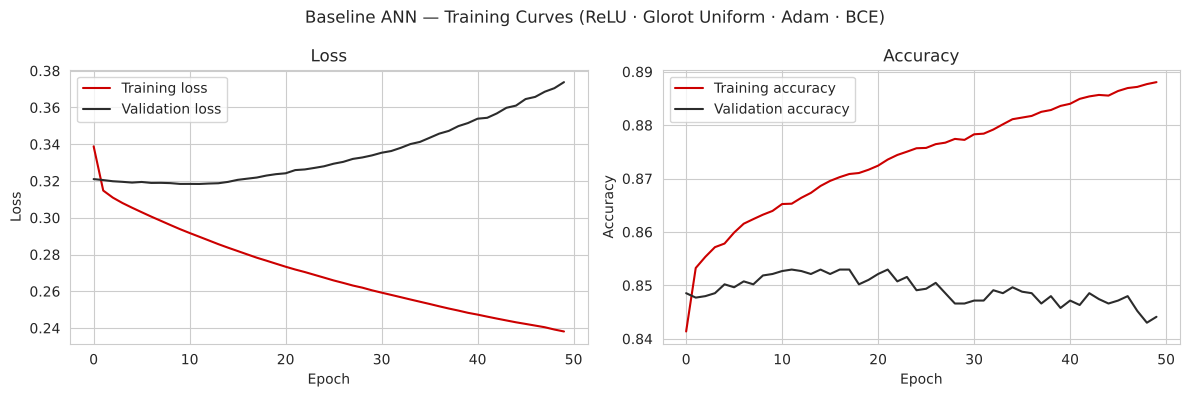

In [10]:
history_base = fit_model(model_base)

h = history_base.history
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(h["loss"], color=RED, label="Training loss")
axes[0].plot(h["val_loss"], color=CHARCOAL, label="Validation loss")
axes[0].set(xlabel="Epoch", ylabel="Loss", title="Loss")
axes[1].plot(h["accuracy"], color=RED, label="Training accuracy")
axes[1].plot(h["val_accuracy"], color=CHARCOAL, label="Validation accuracy")
axes[1].set(xlabel="Epoch", ylabel="Accuracy", title="Accuracy")
axes[0].legend(); axes[1].legend()
fig.suptitle("Baseline ANN — Training Curves (ReLU · Glorot Uniform · Adam · BCE)")
plt.tight_layout()
plt.show()

### Observation: baseline curves


The baseline learns quickly but **overfits early**. Training loss keeps falling (0.34 → 0.24), while validation loss is lowest at around epoch 10 (about 0.319) and then rises to about 0.37. Validation accuracy peaks at about 85.3% (around epochs 10 to 20) and then slips to 84.4%, while training accuracy keeps rising to 88.8%. With 18,689 weights and no regularization or early stopping, the network starts memorising the training rows after roughly 10 to 20 epochs. This matters for the rest of the notebook: every model is trained for a fixed number of epochs, so "less overfitting by the last epoch" often looks like "better".


### 2.4 - Evaluate the baseline

              precision    recall  f1-score   support

       <=50K       0.87      0.91      0.89      6803
        >50K       0.69      0.59      0.64      2242

    accuracy                           0.83      9045
   macro avg       0.78      0.75      0.76      9045
weighted avg       0.83      0.83      0.83      9045



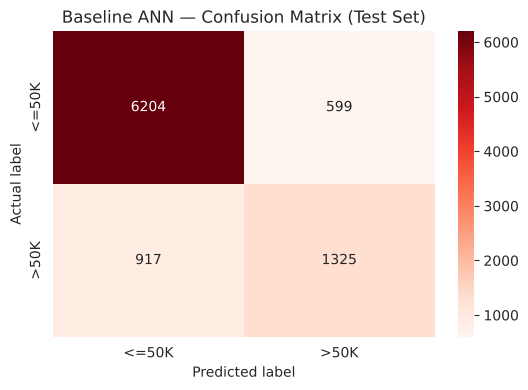

{'Test Acc': 0.8324, 'Prec(1)': 0.6887, 'Recall(1)': 0.591, 'F1(1)': 0.6361, 'ROC-AUC': 0.8855}


In [11]:
y_pred_prob = model_base.predict(X_test, verbose=0).flatten()
y_pred = (y_pred_prob > 0.5).astype(int)

print(classification_report(y_test, y_pred, target_names=["<=50K", ">50K"]))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5.5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Reds", xticklabels=["<=50K", ">50K"], yticklabels=["<=50K", ">50K"])
plt.title("Baseline ANN — Confusion Matrix (Test Set)")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.tight_layout()
plt.show()

base_scores = test_metrics(model_base)
print({k: round(v, 4) for k, v in base_scores.items()})

### Observation: baseline test results


Test accuracy is 83.2%. For class 1 (>50K): **Precision 0.69, Recall 0.59, F1 0.64**, ROC-AUC 0.886. So of all real high earners, the baseline finds only 59% of them. Class 0 looks much better (recall 0.91), which is the effect of the 3 : 1 imbalance. These class-1 numbers go into the final results table.


### 2.5 - WHY tabular data suits an ANN

Images need a CNN and sequences need an RNN, because their inputs have a spatial or time order. Our data is a plain table: each input neuron gets one scaled feature (age, hours per week, one-hot columns, ...) and the hidden layers learn weighted mixes of them. The non-linear layers can learn interactions such as age × education × occupation, which a simple logistic regression cannot capture unless we write those interaction terms by hand. So a fully connected MLP is the natural choice here.

## Task 3: Activation Functions — Comparison Experiment
**Objective:** compare ReLU, Tanh, Sigmoid and ELU as hidden activations and check dead neurons and vanishing gradients.

**Expected output:** 4-panel comparison plot, dead-neuron histogram, gradient bar chart and a summary table.

### 3.1 - Train 4 models with different hidden activations

In [12]:
act_names = ["relu", "tanh", "sigmoid", "elu"]
act_models, act_hist = {}, {}

for name in act_names:
    reset_seed()
    act_models[name] = build_ann(input_dim=X_train.shape[1], activation=name)
    act_hist[name] = fit_model(act_models[name])
    print(name, "| final val acc:", round(act_hist[name].history["val_accuracy"][-1], 4),
          "| final val F1:", round(val_f1(act_hist[name])[-1], 4))

history_relu, history_tanh = act_hist["relu"], act_hist["tanh"]
history_sigmoid, history_elu = act_hist["sigmoid"], act_hist["elu"]
model_relu, model_sigmoid = act_models["relu"], act_models["sigmoid"]

relu | final val acc: 0.8441 | final val F1: 0.6527


tanh | final val acc: 0.8485 | final val F1: 0.6592


sigmoid | final val acc: 0.8574 | final val F1: 0.6795


elu | final val acc: 0.8577 | final val F1: 0.6815


### 3.2 - Activation comparison plot

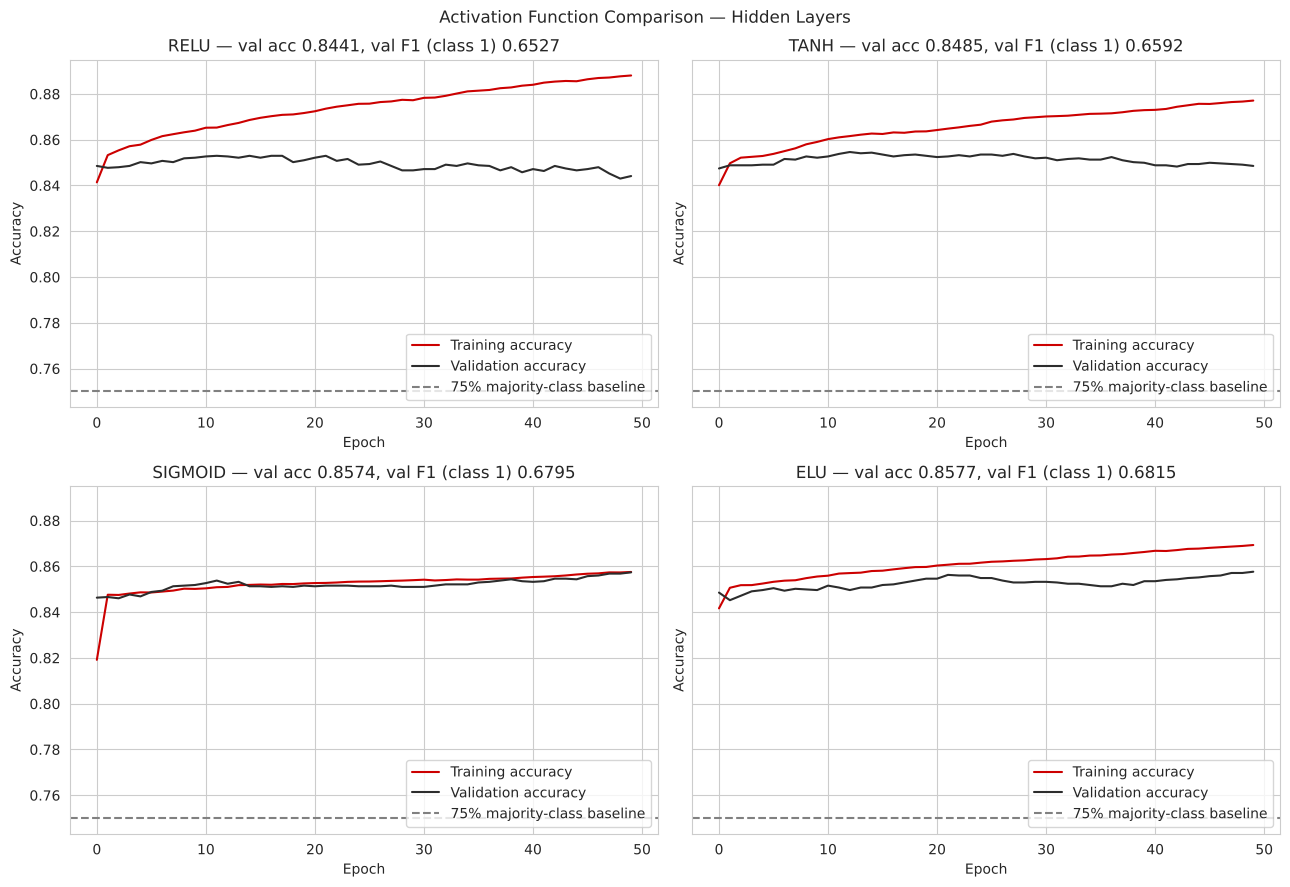

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharey=True)
for ax, name in zip(axes.flatten(), act_names):
    h = act_hist[name].history
    ax.plot(h["accuracy"], color=RED, label="Training accuracy")
    ax.plot(h["val_accuracy"], color=CHARCOAL, label="Validation accuracy")
    ax.axhline(0.75, color="grey", linestyle="--", label="75% majority-class baseline")
    ax.set_title(f"{name.upper()} — val acc {h['val_accuracy'][-1]:.4f}, val F1 (class 1) {val_f1(act_hist[name])[-1]:.4f}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy")
    ax.legend(loc="lower right")
fig.suptitle("Activation Function Comparison — Hidden Layers")
plt.tight_layout()
plt.savefig("plots/activation_comparison.png", dpi=120)
plt.show()

### 3.3 - Dead neuron check — ReLU

Fraction of activations that are exactly 0: 0.6138
Neurons that are 0 for all 500 samples: 0 out of 128


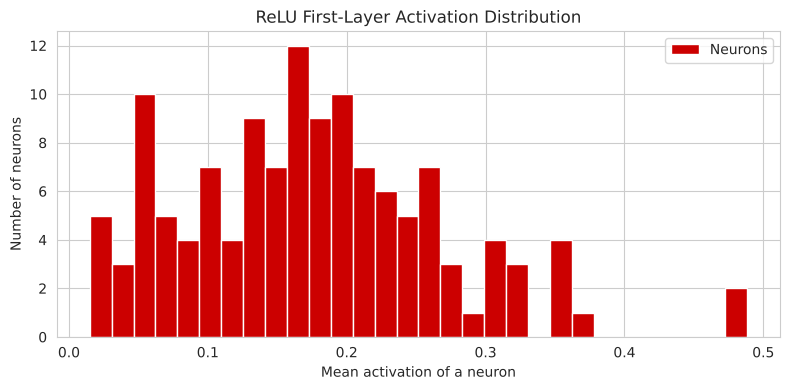

In [14]:
# outputs of the first hidden layer (after ReLU) for 500 test samples
intermediate = keras.Model(inputs=model_relu.inputs, outputs=model_relu.layers[1].output)
activations = intermediate.predict(X_test[:500], verbose=0)

dead_fraction = np.mean(activations == 0)
always_dead = int((activations.max(axis=0) == 0).sum())
print("Fraction of activations that are exactly 0:", round(dead_fraction, 4))
print("Neurons that are 0 for all 500 samples:", always_dead, "out of", activations.shape[1])

plt.figure(figsize=(8, 4))
plt.hist(activations.mean(axis=0), bins=30, color=RED, label="Neurons")
plt.title("ReLU First-Layer Activation Distribution")
plt.xlabel("Mean activation of a neuron")
plt.ylabel("Number of neurons")
plt.legend()
plt.tight_layout()
plt.show()

### Observation: dead neurons


**dead_fraction = 0.614**: 61.4% of the first-layer activations are exactly 0. This is normal for ReLU (a negative input gives 0, so about half or more of the outputs are 0 for any sample) and does not mean the neurons are dead. A neuron is really *dead* only if it is 0 for every sample, and here **0 out of 128** neurons are 0 on all 500 samples, so there is no dying-ReLU problem in this run.

**How ELU avoids it:** ELU gives `α(eˣ − 1)` for x < 0. This is a small negative number, not 0, so the gradient is still non-zero for negative inputs and a neuron can always recover.


### 3.4 - Gradient flow check — Sigmoid hidden layers

         Before training  After 50 epochs
Layer 1         0.000146         0.000235
Layer 2         0.002801         0.000280
Output          0.079642         0.004721


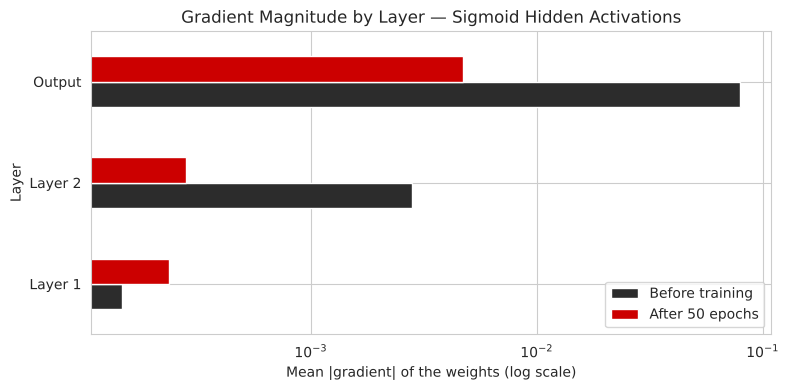

In [15]:
def layer_gradients(model):
    x_batch, y_batch = X_train[:64], y_train[:64]
    with tf.GradientTape() as tape:
        pred = model(x_batch, training=True)
        loss = tf.reduce_mean(keras.losses.binary_crossentropy(y_batch.reshape(-1, 1), pred))
    grads = tape.gradient(loss, model.trainable_variables)
    # grads[0], grads[2], grads[4] are the weights (kernels) of Layer 1, Layer 2 and Output
    return [float(np.mean(np.abs(grads[i].numpy()))) for i in (0, 2, 4)]

reset_seed()
fresh_sigmoid = build_ann(input_dim=X_train.shape[1], activation="sigmoid")

grad_table = pd.DataFrame({"Before training": layer_gradients(fresh_sigmoid),
                           "After 50 epochs": layer_gradients(model_sigmoid)},
                          index=["Layer 1", "Layer 2", "Output"])
print(grad_table)

grad_table.plot(kind="barh", figsize=(8, 4), color=[CHARCOAL, RED], logx=True)
plt.title("Gradient Magnitude by Layer — Sigmoid Hidden Activations")
plt.xlabel("Mean |gradient| of the weights (log scale)")
plt.ylabel("Layer")
plt.legend()
plt.tight_layout()
plt.show()

### Observation: gradient flow


Mean |gradient| of the weights in the sigmoid-hidden model, **before training**: Layer 1 = 0.00015, Layer 2 = 0.0028, Output = 0.080. The output layer gets gradients about **550 times larger** than Layer 1, so the first layer learns much more slowly. That is the vanishing gradient. After 50 epochs the gradients are smaller everywhere (0.00024, 0.00028, 0.0047), and the model is close to a flat region of the loss.

**Why:** the sigmoid derivative is `σ'(x) = σ(x)(1 − σ(x)) ≤ 0.25`. During backpropagation the gradient is multiplied by this number (and by the weights) at every sigmoid layer, so it shrinks about by a factor of 4 or more per layer.


### 3.5 - Activation summary table

### Summary: activation functions


| Activation | Formula | Output range | Zero-centred | Vanishing gradient | Dead neuron risk | Val acc (this run) | Val F1 class 1 |
|---|---|---|---|---|---|---|---|
| ReLU | max(0, x) | [0, ∞) | No | No (for x > 0) | Yes (0 gradient for x < 0) | 0.8441 | 0.6527 |
| Tanh | (eˣ − e⁻ˣ)/(eˣ + e⁻ˣ) | (−1, 1) | Yes | Yes, for large \|x\| | No | 0.8485 | 0.6592 |
| Sigmoid (hidden) | 1/(1 + e⁻ˣ) | (0, 1) | No | Yes, σ' ≤ 0.25 | No | 0.8574 | 0.6795 |
| ELU | x if x > 0, else α(eˣ − 1) | (−α, ∞) | Almost | No | No | 0.8577 | 0.6815 |
| Sigmoid (output layer only) | 1/(1 + e⁻ˣ) | (0, 1) | — | — | — | always correct for a binary output | — |

**Recommendation:** for this dataset and setup I would use **ELU**: it has the best validation accuracy and F1 (0.8577 / 0.6815), and its test F1 (0.673) and ROC-AUC (0.906) are the best in the final table. The sigmoid output layer is always correct for a binary target, whichever hidden activation is used.

**Be careful with the ranking.** The differences between the four are small (about 1.4 points of accuracy), I used one seed, and the picture is partly about overfitting: ReLU and Tanh reach a high training accuracy and then overfit, while Sigmoid and ELU learn more slowly, so after 50 epochs they have overfitted less. Hidden Sigmoid is still a poor general choice (see the gradient check). It works here only because the network has just two hidden layers.


## Task 4: Weight Initialization Techniques
**Objective:** compare five weight initialisers and show why all-zero weights fail.

**Expected output:** convergence plot, zeros failure plot, 2×2 weight histograms.

### 4.1 - Train 5 models with different initialisers

### 4.2 - WHY initialisation matters

- **Zeros:** if all weights are 0, every neuron in a layer gives the same output, gets the same gradient and is updated to the same value. This is the *symmetry problem*: the layer behaves like a single neuron, however wide it is.
- **Glorot / Xavier:** draws weights with variance `2 / (fan_in + fan_out)`. It keeps the size of activations and gradients about the same from layer to layer, which suits tanh and sigmoid.
- **He:** uses variance `2 / fan_in`. ReLU sets about half of the activations to zero, so the extra factor 2 keeps the variance stable for ReLU networks.

In [16]:
init_names = ["glorot_uniform", "glorot_normal", "he_uniform", "he_normal", "zeros"]
init_models, init_hist, init_w0 = {}, {}, {}

for name in init_names:
    reset_seed()
    init_models[name] = build_ann(input_dim=X_train.shape[1], activation="relu", initializer=name)
    init_w0[name] = init_models[name].layers[0].get_weights()[0].copy()    # weights before training
    init_hist[name] = fit_model(init_models[name])
    print(name, "| final val acc:", round(init_hist[name].history["val_accuracy"][-1], 4),
          "| final val F1:", round(val_f1(init_hist[name])[-1], 4))

glorot_uniform | final val acc: 0.8441 | final val F1: 0.6527


glorot_normal | final val acc: 0.8411 | final val F1: 0.6487


he_uniform | final val acc: 0.8389 | final val F1: 0.6377


he_normal | final val acc: 0.8331 | final val F1: 0.6276


zeros | final val acc: 0.7526 | final val F1: 0.0


### 4.3 - Convergence speed comparison

glorot_uniform - first epoch with val acc >= 82%: 1
glorot_normal - first epoch with val acc >= 82%: 1
he_uniform - first epoch with val acc >= 82%: 1
he_normal - first epoch with val acc >= 82%: 1
zeros - first epoch with val acc >= 82%: None


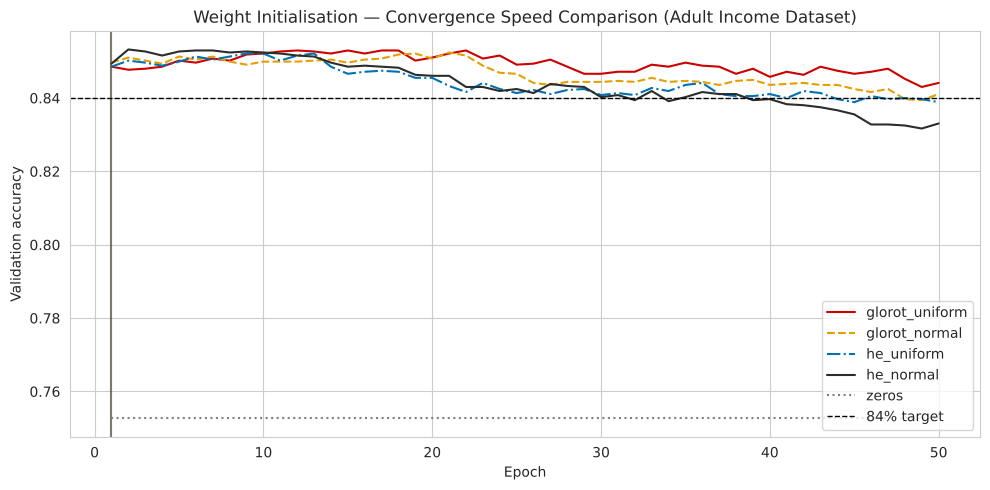

In [17]:
styles = {"glorot_uniform": ("-", RED), "glorot_normal": ("--", "#E69F00"), "he_uniform": ("-.", "#0072B2"),
          "he_normal": ("-", CHARCOAL), "zeros": (":", "grey")}

plt.figure(figsize=(10, 5))
for name in init_names:
    ls, col = styles[name]
    va = init_hist[name].history["val_accuracy"]
    plt.plot(range(1, len(va) + 1), va, linestyle=ls, color=col, label=name)
    first = next((i + 1 for i, v in enumerate(va) if v >= 0.82), None)
    if first and name != "zeros":
        plt.axvline(first, color=col, alpha=0.3)
    print(name, "- first epoch with val acc >= 82%:", first)
plt.axhline(0.84, color="black", linestyle="--", linewidth=1, label="84% target")
plt.title("Weight Initialisation — Convergence Speed Comparison (Adult Income Dataset)")
plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("plots/initialiser_convergence.png", dpi=120)
plt.show()

### Observation: convergence


This did **not** match the textbook story. All four non-zero initialisers start at about 84.5% to 85% validation accuracy after epoch 1, so they all cross 82% at **epoch 1** (the vertical line) and the 82% mark cannot tell them apart. After that all of them *peak early (around epochs 5 to 20, about 85.3%) and then decline* because of overfitting, and the one with the highest final value is simply the one that overfits least by epoch 50: Glorot uniform 0.844, Glorot normal 0.841, He uniform 0.839, He normal 0.833. None of them reaches the 84% target at the end except Glorot uniform and Glorot normal (barely).

So on this small, shallow (2 hidden layers) network the initialiser has almost no effect on how fast it learns. The He advantage appears in deeper ReLU networks. The only large difference is **zeros**, which stays flat at 75.3%.


### 4.4 - Zeros failure demonstration

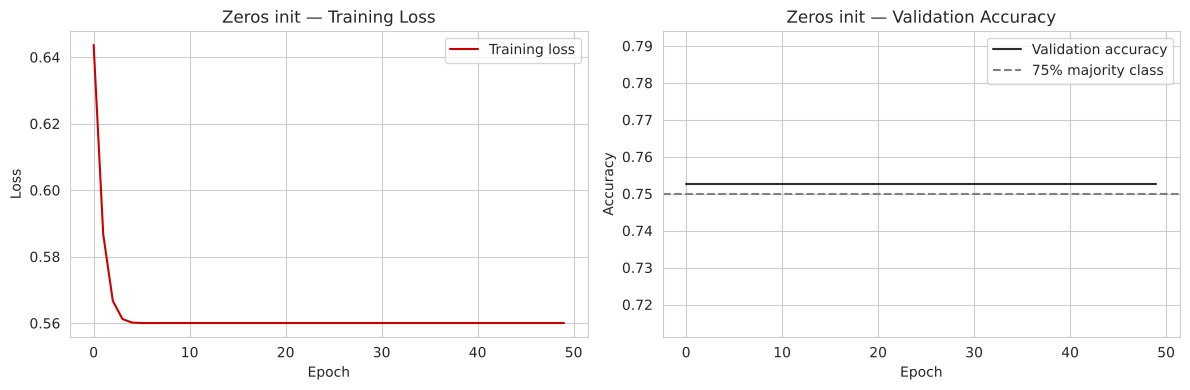

Class-1 recall on validation (last epoch): 0.0


In [18]:
h = init_hist["zeros"].history
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(h["loss"], color=RED, label="Training loss")
axes[0].set(title="Zeros init — Training Loss", xlabel="Epoch", ylabel="Loss")
axes[1].plot(h["val_accuracy"], color=CHARCOAL, label="Validation accuracy")
axes[1].axhline(0.75, color="grey", linestyle="--", label="75% majority class")
axes[1].set(title="Zeros init — Validation Accuracy", xlabel="Epoch", ylabel="Accuracy")
axes[0].legend(); axes[1].legend()
plt.tight_layout()
plt.show()

print("Class-1 recall on validation (last epoch):", round(h["val_recall"][-1], 4))

### Observation: why zeros fails


With zero weights the validation accuracy stays at **75.3% for all 50 epochs** and class-1 recall is **0.0**: the network predicts "<=50K" for everybody, which is exactly the majority-class rate. The training loss falls quickly to **0.560** and stops there. That number is the entropy of the class ratio (0.248 vs 0.752), which is the best a model can do if it ignores all features.

Why: all hidden weights are 0, so all hidden neurons output the same value and receive the same (and, with a zero downstream weight, zero) gradient. They never differ from each other, so only the output bias can learn, and the bias just learns the class ratio. This is the symmetry problem.


### 4.5 - Weight distribution visualisation

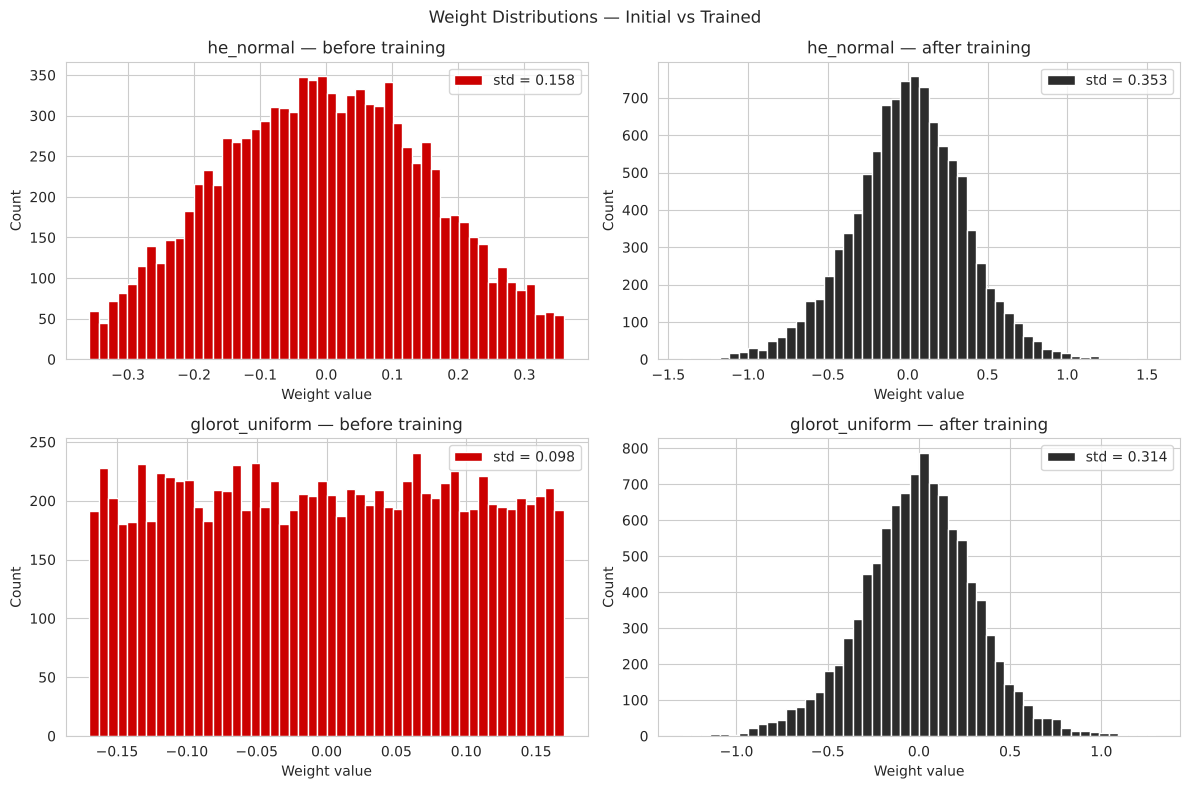

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
panels = [("he_normal", "before"), ("he_normal", "after"), ("glorot_uniform", "before"), ("glorot_uniform", "after")]
for ax, (name, when) in zip(axes.flatten(), panels):
    w = init_w0[name] if when == "before" else init_models[name].layers[0].get_weights()[0]
    ax.hist(w.flatten(), bins=50, color=RED if when == "before" else CHARCOAL, label=f"std = {w.std():.3f}")
    ax.set_title(f"{name} — {when} training")
    ax.set_xlabel("Weight value")
    ax.set_ylabel("Count")
    ax.legend()
fig.suptitle("Weight Distributions — Initial vs Trained")
plt.tight_layout()
plt.savefig("plots/weight_distributions.png", dpi=120)
plt.show()

### Observation: weight distributions


**Before training** the shapes match the theory: Glorot uniform is flat between about ±0.17 (std 0.098), and He normal is bell-shaped and wider (std 0.158). Keras draws He normal from a truncated normal (cut at 2 std), so it stops at about ±0.36. He is wider than Glorot, as expected, because it uses variance 2/fan_in and not 2/(fan_in + fan_out).

**After 50 epochs** both are bell-shaped, wider (std 0.353 and 0.314) and similar to each other. Training moved the weights far from where they started (the initial range was about ±0.36, and after training some weights are beyond ±1). So the initialiser only decides the starting point; backpropagation reshapes the distribution.


## Task 5: Loss Functions
**Objective:** compare Binary Cross-Entropy, MSE, Weighted BCE and Focal Loss, especially for the minority class.

**Expected output:** MSE vs BCE F1 plot, weighted BCE metrics, focal loss metrics and a loss summary table.

### 5.1 - Binary Cross-Entropy — the correct loss

The baseline uses `binary_crossentropy`: `L = −[y·log(p) + (1−y)·log(1−p)]`, where p is the sigmoid output and y is the true label (0 or 1). If the model is confident and wrong (p close to 1 but y = 0), `log(1−p)` goes towards −∞, so the loss becomes very large. It is the negative log-likelihood of a Bernoulli distribution, which is the natural choice for a yes/no target.

### 5.2 - MSE as classification loss — the wrong tool

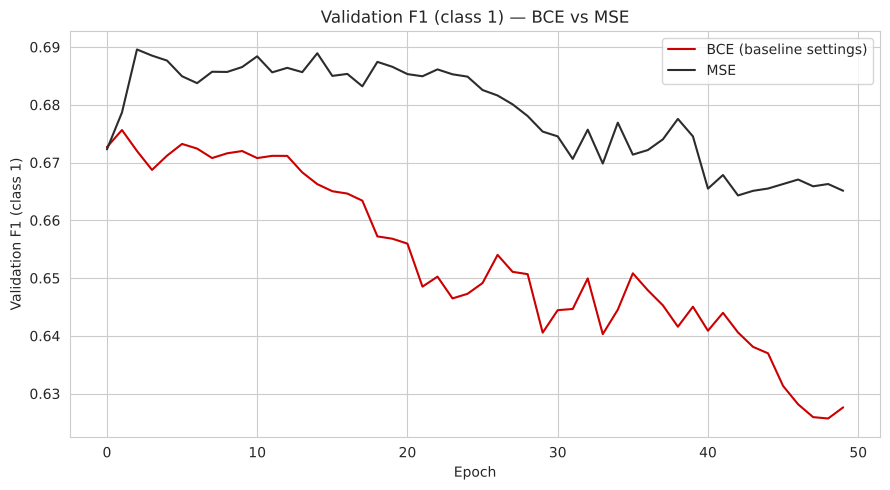

MSE test: {'Test Acc': 0.8348, 'Prec(1)': 0.6751, 'Recall(1)': 0.6432, 'F1(1)': 0.6587, 'ROC-AUC': 0.8898}


BCE test: {'Test Acc': 0.83, 'Prec(1)': 0.6841, 'Recall(1)': 0.5834, 'F1(1)': 0.6298, 'ROC-AUC': 0.8812}


In [20]:
reset_seed()
model_mse = build_ann(input_dim=X_train.shape[1], activation="relu", initializer="he_normal", loss="mean_squared_error")
history_mse = fit_model(model_mse)

# baseline for the loss comparison: same settings but he_normal and BCE (from Task 2 it used glorot_uniform)
history_bce_he = init_hist["he_normal"]
model_bce_he = init_models["he_normal"]

plt.figure(figsize=(9, 5))
plt.plot(val_f1(history_bce_he), color=RED, label="BCE (baseline settings)")
plt.plot(val_f1(history_mse), color=CHARCOAL, label="MSE")
plt.title("Validation F1 (class 1) — BCE vs MSE")
plt.xlabel("Epoch")
plt.ylabel("Validation F1 (class 1)")
plt.legend()
plt.tight_layout()
plt.show()

print("MSE test:", {k: round(v, 4) for k, v in test_metrics(model_mse).items()})
print("BCE test:", {k: round(v, 4) for k, v in test_metrics(model_bce_he).items()})

### Observation: BCE vs MSE


MSE treats the sigmoid output as a regression target. Its gradient for the output neuron contains σ'(z) = p(1 − p), which goes to 0 when the output saturates, so a confidently wrong prediction learns very slowly. The BCE gradient is simply (p − y), which is large when the model is wrong.

**In my run MSE was not worse.** Test class-1 F1: MSE **0.659** vs BCE **0.630** (recall 0.64 vs 0.58, ROC-AUC 0.890 vs 0.881). I think the reason is that the validation F1 of the BCE model falls after its early peak because it overfits more strongly, while the weaker MSE gradient slows its overfitting. With one run and 9,045 test rows this 0.03 gap is a small effect, and I cannot claim MSE is better. The theory (BCE has the better gradient) is still correct, but here it did not show up in the F1.


### 5.3 - Weighted Binary Cross-Entropy

Class weights: {0: np.float64(0.6647495498144133), 1: np.float64(2.0174548293553425)}


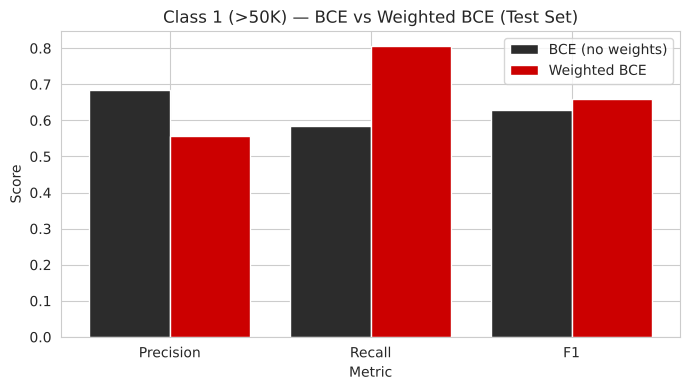

In [21]:
weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
class_weight_dict = {0: weights[0], 1: weights[1]}
print("Class weights:", class_weight_dict)

reset_seed()
model_wbce = build_ann(input_dim=X_train.shape[1], activation="relu", initializer="he_normal")
history_wbce = fit_model(model_wbce, class_weight=class_weight_dict)

m_bce = test_metrics(model_bce_he)
m_wbce = test_metrics(model_wbce)

labels = ["Precision", "Recall", "F1"]
x = np.arange(3)
plt.figure(figsize=(7, 4))
plt.bar(x - 0.2, [m_bce["Prec(1)"], m_bce["Recall(1)"], m_bce["F1(1)"]], 0.4, color=CHARCOAL, label="BCE (no weights)")
plt.bar(x + 0.2, [m_wbce["Prec(1)"], m_wbce["Recall(1)"], m_wbce["F1(1)"]], 0.4, color=RED, label="Weighted BCE")
plt.xticks(x, labels)
plt.title("Class 1 (>50K) — BCE vs Weighted BCE (Test Set)")
plt.xlabel("Metric")
plt.ylabel("Score")
plt.legend()
plt.tight_layout()
plt.show()

### Observation: weighted BCE


Class weights computed with `'balanced'` are 0.66 for class 0 and 2.02 for class 1. With weighting, **Recall of class 1 rose from 0.58 to 0.81** (a much larger share of high earners is found), **Precision fell from 0.68 to 0.56**, and F1 went from 0.630 to 0.659. This is the expected trade-off: errors on the minority class cost about 3 times more, so the model predicts ">50K" more often. This is useful when missing a high earner is more costly than a false positive (income targeting), and less useful when false positives are costly.


### 5.4 - Focal Loss

              Prec(1)  Recall(1)   F1(1)
BCE            0.6841     0.5834  0.6298
MSE            0.6751     0.6432  0.6587
Weighted BCE   0.5571     0.8073  0.6593
Focal          0.7785     0.3840  0.5143


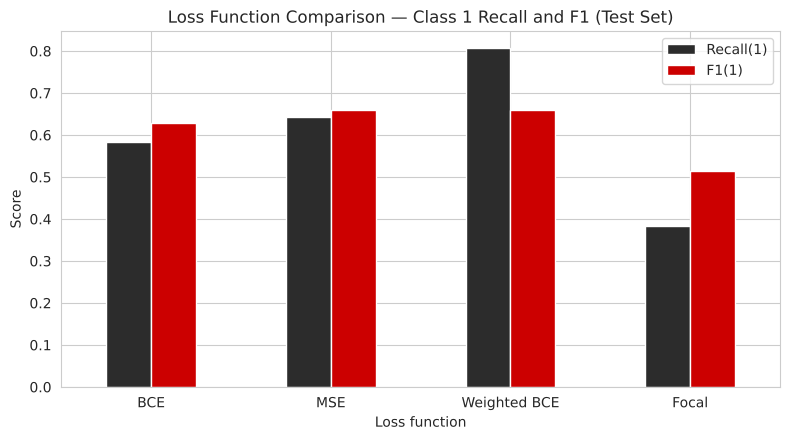

In [22]:
def focal_loss(gamma=2.0, alpha=0.25):
    def loss(y_true, y_pred):
        y_true = tf.cast(y_true, tf.float32)
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1 - 1e-7)
        bce = -y_true * tf.math.log(y_pred) - (1 - y_true) * tf.math.log(1 - y_pred)
        weight = alpha * y_true * (1 - y_pred) ** gamma + (1 - alpha) * (1 - y_true) * y_pred ** gamma
        return tf.reduce_mean(weight * bce)
    return loss

reset_seed()
model_focal = build_ann(input_dim=X_train.shape[1], activation="relu", initializer="he_normal", loss=focal_loss())
history_focal = fit_model(model_focal)

m_focal = test_metrics(model_focal)
m_mse = test_metrics(model_mse)

loss_scores = pd.DataFrame({"BCE": m_bce, "MSE": m_mse, "Weighted BCE": m_wbce, "Focal": m_focal}).T
print(loss_scores[["Prec(1)", "Recall(1)", "F1(1)"]].round(4))

loss_scores[["Recall(1)", "F1(1)"]].plot(kind="bar", figsize=(8, 4.5), color=[CHARCOAL, RED], rot=0)
plt.title("Loss Function Comparison — Class 1 Recall and F1 (Test Set)")
plt.xlabel("Loss function")
plt.ylabel("Score")
plt.legend()
plt.tight_layout()
plt.savefig("plots/loss_f1_comparison.png", dpi=120)
plt.show()

### Observation: focal loss


With `gamma=2, alpha=0.25` (as in the brief) the Focal Loss model was the **worst** for the minority class: Precision 0.78 but **Recall only 0.38**, F1 0.514, accuracy 82.0%. The reason is `alpha = 0.25`: it multiplies the loss of class 1 by 0.25 and the loss of class 0 by 0.75, which makes the model *more* cautious about predicting class 1, the opposite of what we want here. The `(1 − p)^gamma` part (focus on hard examples) is not the issue.

So focal loss with the default settings is not a good fit for this problem. Using alpha = 0.75 (more weight on class 1) or gamma = 1 would be the next thing to try; I kept the values from the brief.


### 5.5 - Loss function summary table

### Summary: loss functions


| Loss function | Formula (simplified) | Best for | Imbalance handling | Class-1 F1 on Adult (test) |
|---|---|---|---|---|
| BCE | −[y·log p + (1−y)·log(1−p)] | Balanced binary classification | None | 0.630 |
| Weighted BCE | −[w₁·y·log p + w₀·(1−y)·log(1−p)] | Imbalanced data when Recall of the minority class matters | Class weights (w₁ = 2.02, w₀ = 0.66) | 0.659 (Recall 0.81) |
| MSE (classification) | (y − p)² | Regression, not recommended for classification | None | 0.659 |
| Focal Loss | −α·(1−p)^γ·y·log p − (1−α)·p^γ·(1−y)·log(1−p) | Extreme imbalance with many easy examples | Down-weights easy examples, alpha re-weights classes | 0.514 (Recall 0.38) |

**Recommendation for production:** **Weighted BCE**. It has the best Recall for >50K (0.81) with the best-tied F1, it is simple, and its behaviour is easy to explain. MSE gives a similar F1 by luck of overfitting, and focal loss with these parameters hurts Recall. If Precision matters more than Recall, plain BCE with a threshold tuned on validation data is the other good option.


## Task 6: Batch Normalization
**Objective:** add Batch Normalization to the ANN and see how it changes training.

**Expected output:** summary with BN parameters, with vs without BN plot, BN position comparison, gamma/beta bar charts.

### 6.1 - Build ANN with Batch Normalization

In [23]:
reset_seed()
model_bn = keras.Sequential([
    keras.Input(shape=(X_train.shape[1],)),
    keras.layers.Dense(128, kernel_initializer="he_normal"),
    keras.layers.BatchNormalization(),
    keras.layers.Activation("relu"),
    keras.layers.Dense(64, kernel_initializer="he_normal"),
    keras.layers.BatchNormalization(),
    keras.layers.Activation("relu"),
    keras.layers.Dense(1, activation="sigmoid")
])
model_bn.compile(optimizer="adam", loss="binary_crossentropy",
                 metrics=["accuracy", keras.metrics.Precision(name="precision"), keras.metrics.Recall(name="recall")])
model_bn.summary()

Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_42 (Dense)                │ (None, 128)            │        10,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_28 (Activation)      │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_43 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_29 (Activation)      │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_44 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,457 (76.00 KB)

 Trainable params: 19,073 (74.50 KB)

 Non-trainable params: 384 (1.50 KB)

Each BatchNormalization layer has 4 × neurons parameters: gamma, beta, moving mean and moving variance (128 × 4 = 512 and 64 × 4 = 256). Only gamma and beta are trainable. The moving mean and variance are not trained by gradients, they are updated as running averages.

### 6.2 - WHY Batch Normalization

While training, the weights of every layer change, so the distribution of inputs that the next layer sees keeps changing too. This is called **Internal Covariate Shift** (Ioffe & Szegedy, 2015): each layer is always chasing a moving target. Batch Normalization fixes the pre-activation values of each mini-batch to mean 0 and variance 1, and then applies a learnable scale (γ) and shift (β): `BN(x) = γ · (x − μ_B) / √(σ²_B + ε) + β`.

During **training** it uses the mean and variance of the current batch. At **inference** it uses the running averages collected during training, so predictions do not depend on the other samples in the batch. Benefits on tabular data: faster convergence, less sensitivity to the learning rate, and a small regularisation effect (batch statistics add noise).

### 6.3 - Train and compare: with vs without BatchNorm

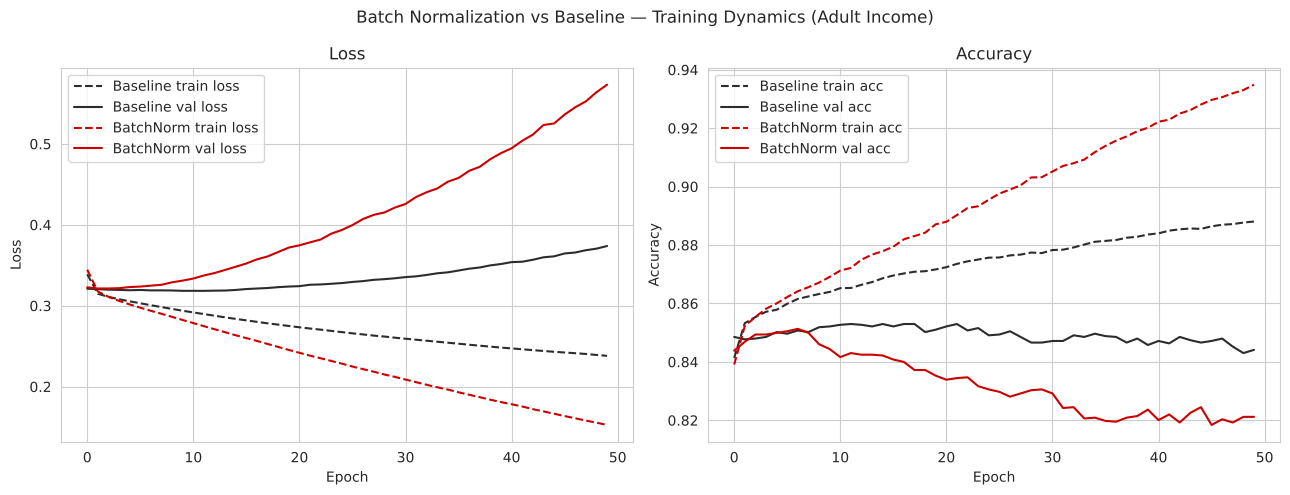

Baseline test: acc 0.8324 | F1(1) 0.6361
BatchNorm test: acc 0.8195 | F1(1) 0.5781


In [24]:
history_bn = fit_model(model_bn)

hb, hn = history_base.history, history_bn.history
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(hb["loss"], color=CHARCOAL, linestyle="--", label="Baseline train loss")
axes[0].plot(hb["val_loss"], color=CHARCOAL, label="Baseline val loss")
axes[0].plot(hn["loss"], color=RED, linestyle="--", label="BatchNorm train loss")
axes[0].plot(hn["val_loss"], color=RED, label="BatchNorm val loss")
axes[0].set(xlabel="Epoch", ylabel="Loss", title="Loss")
axes[1].plot(hb["accuracy"], color=CHARCOAL, linestyle="--", label="Baseline train acc")
axes[1].plot(hb["val_accuracy"], color=CHARCOAL, label="Baseline val acc")
axes[1].plot(hn["accuracy"], color=RED, linestyle="--", label="BatchNorm train acc")
axes[1].plot(hn["val_accuracy"], color=RED, label="BatchNorm val acc")
axes[1].set(xlabel="Epoch", ylabel="Accuracy", title="Accuracy")
axes[0].legend(); axes[1].legend()
fig.suptitle("Batch Normalization vs Baseline — Training Dynamics (Adult Income)")
plt.tight_layout()
plt.savefig("plots/batchnorm_dynamics.png", dpi=120)
plt.show()

m_bn = test_metrics(model_bn)
print("Baseline test: acc", round(base_scores["Test Acc"], 4), "| F1(1)", round(base_scores["F1(1)"], 4))
print("BatchNorm test: acc", round(m_bn["Test Acc"], 4), "| F1(1)", round(m_bn["F1(1)"], 4))

### Observation: with vs without BatchNorm


This is the opposite of the expected result. **BatchNorm trains faster but overfits more:** its training loss falls from 0.34 to 0.15 (baseline: 0.24) and its training accuracy reaches 93.5% (baseline: 88.8%), but its validation loss rises sharply from about epoch 5 (to 0.57, baseline 0.37) and its validation accuracy drops to about 82%.

On the test set: baseline accuracy 0.832 / F1 0.636; BatchNorm accuracy **0.819** / F1 **0.578**. So here BN **did not** give a tighter train-validation gap (the gap is wider), it gave faster convergence on the training data only. The "mild regularisation effect" of BN is small and does not stop a 128-64 network from memorising 36,000 rows over 50 epochs. BN is useful for speed and stability, but it is not a replacement for Dropout, L2 or Early Stopping, which is what PR 1 was about.


### 6.4 - BatchNorm position experiment

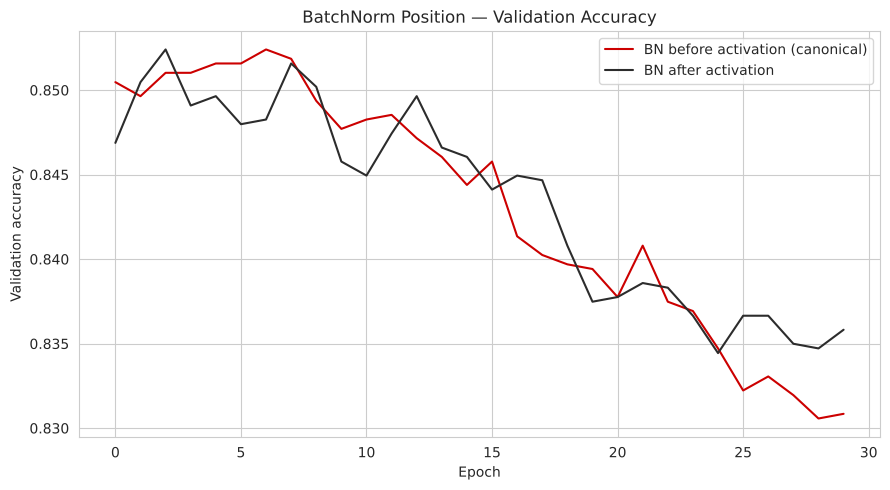

BN before activation | mean val acc (last 10 epochs): 0.8346 | test F1(1): 0.6367


BN after activation  | mean val acc (last 10 epochs): 0.8365 | test F1(1): 0.6279


In [25]:
reset_seed()
model_bn_after = keras.Sequential([
    keras.Input(shape=(X_train.shape[1],)),
    keras.layers.Dense(128, activation="relu", kernel_initializer="he_normal"),
    keras.layers.BatchNormalization(),
    keras.layers.Dense(64, activation="relu", kernel_initializer="he_normal"),
    keras.layers.BatchNormalization(),
    keras.layers.Dense(1, activation="sigmoid")
])
model_bn_after.compile(optimizer="adam", loss="binary_crossentropy",
                       metrics=["accuracy", keras.metrics.Precision(name="precision"), keras.metrics.Recall(name="recall")])
history_bn_after = fit_model(model_bn_after, epochs=30)

reset_seed()
model_bn_before = build_ann(input_dim=X_train.shape[1], initializer="he_normal", use_batch_norm=True)
history_bn_before = fit_model(model_bn_before, epochs=30)

plt.figure(figsize=(9, 5))
plt.plot(history_bn_before.history["val_accuracy"], color=RED, label="BN before activation (canonical)")
plt.plot(history_bn_after.history["val_accuracy"], color=CHARCOAL, label="BN after activation")
plt.title("BatchNorm Position — Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.legend()
plt.tight_layout()
plt.show()

print("BN before activation | mean val acc (last 10 epochs):", round(np.mean(history_bn_before.history["val_accuracy"][-10:]), 4),
      "| test F1(1):", round(test_metrics(model_bn_before)["F1(1)"], 4))
print("BN after activation  | mean val acc (last 10 epochs):", round(np.mean(history_bn_after.history["val_accuracy"][-10:]), 4),
      "| test F1(1):", round(test_metrics(model_bn_after)["F1(1)"], 4))

### Observation: BN position


Both orders show the same overfitting pattern (validation accuracy peaks near 85% in the first 8 epochs and then declines to about 83%). Mean validation accuracy over the last 10 epochs: BN before activation **0.8346**, BN after activation **0.8365**; test F1 (class 1): **0.6367** vs **0.6279**. The difference is below 1 point and the curves cross each other, so I cannot say either order is better. I ran each only once, so I cannot say anything about statistical significance (that would need several seeds). I keep the canonical order (BN before activation) in the rest of the notebook.


### 6.5 - Inspect learned gamma and beta

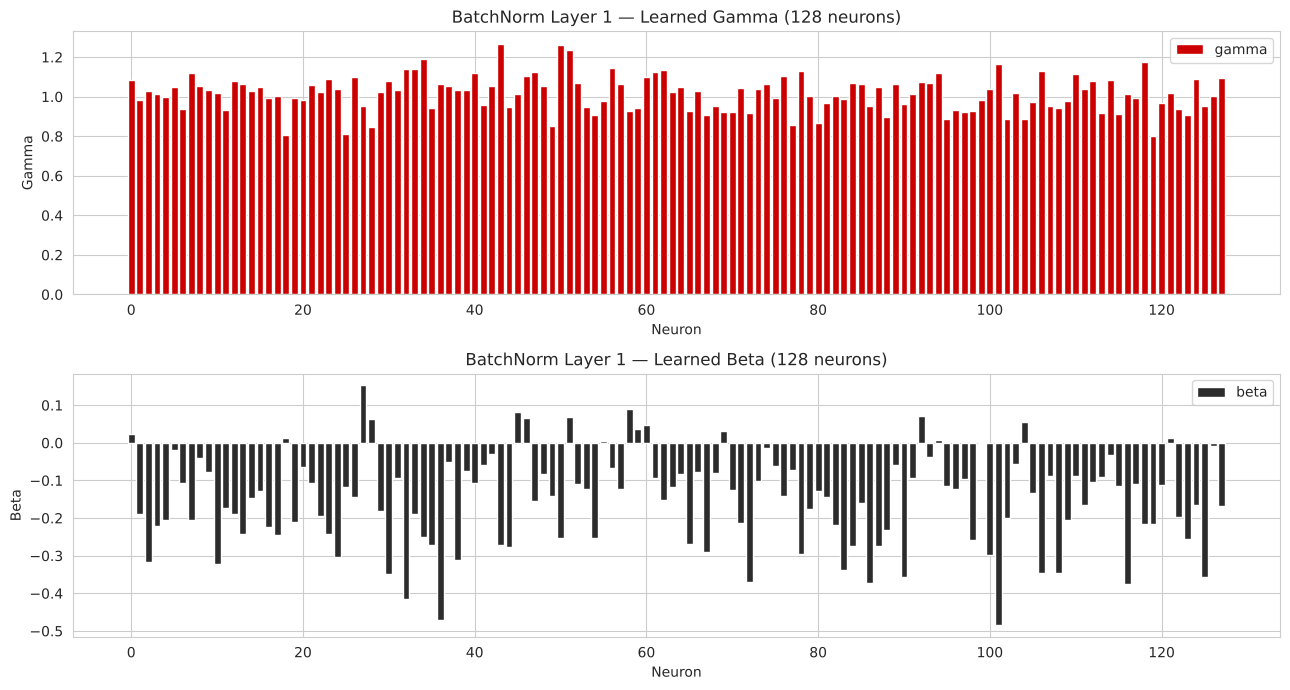

Neurons with |gamma| < 0.1: 0 out of 128
gamma min / mean / max: 0.803 1.016 1.269


In [26]:
bn_layer = [l for l in model_bn.layers if isinstance(l, keras.layers.BatchNormalization)][0]
gamma, beta, running_mean, running_var = bn_layer.get_weights()

fig, axes = plt.subplots(2, 1, figsize=(13, 7))
axes[0].bar(range(128), gamma, color=RED, label="gamma")
axes[0].set(title="BatchNorm Layer 1 — Learned Gamma (128 neurons)", xlabel="Neuron", ylabel="Gamma")
axes[1].bar(range(128), beta, color=CHARCOAL, label="beta")
axes[1].set(title="BatchNorm Layer 1 — Learned Beta (128 neurons)", xlabel="Neuron", ylabel="Beta")
axes[0].legend(); axes[1].legend()
plt.tight_layout()
plt.show()

print("Neurons with |gamma| < 0.1:", int((np.abs(gamma) < 0.1).sum()), "out of 128")
print("gamma min / mean / max:", gamma.min().round(3), gamma.mean().round(3), gamma.max().round(3))

### Observation: gamma and beta


After training, all 128 gamma values are between **0.80 and 1.27** (mean 1.02), and **0 neurons have |gamma| < 0.1**. So BatchNorm did not switch off any neuron: gamma stayed close to its starting value of 1, because the first-layer inputs are already informative (scaled numeric columns and one-hot columns) and the model learns more by changing weights than by rescaling. Neurons with the largest gamma (above 1.2) are the ones the network amplifies the most.


## Task 7: Optimizers — Convergence & Final Comparison
**Objective:** compare five optimizers and the learning rate, then build and compare the final model.

**Expected output:** optimizer convergence plot, learning rate sensitivity plot, final model metrics, results table and ROC curves.

### 7.1 - Build 5 models with different optimizers

In [27]:
def make_optimizer(name):
    if name == "sgd":
        return keras.optimizers.SGD(learning_rate=0.01)
    if name == "sgd_momentum":
        return keras.optimizers.SGD(learning_rate=0.01, momentum=0.9)
    if name == "rmsprop":
        return "rmsprop"
    if name == "adam":
        return "adam"
    return keras.optimizers.Adam(learning_rate=0.001, beta_1=0.9, beta_2=0.999)   # adam_explicit

opt_names = ["sgd", "sgd_momentum", "rmsprop", "adam", "adam_explicit"]
opt_models, opt_hist = {}, {}

for name in opt_names:
    reset_seed()
    opt_models[name] = build_ann(input_dim=X_train.shape[1], activation="relu", initializer="he_normal",
                                 use_batch_norm=True, optimizer=make_optimizer(name))
    opt_hist[name] = fit_model(opt_models[name])
    print(name, "| final val acc:", round(opt_hist[name].history["val_accuracy"][-1], 4),
          "| final val F1:", round(val_f1(opt_hist[name])[-1], 4))

sgd | final val acc: 0.8513 | final val F1: 0.6771


sgd_momentum | final val acc: 0.8242 | final val F1: 0.6228


rmsprop | final val acc: 0.8212 | final val F1: 0.5954


adam | final val acc: 0.8237 | final val F1: 0.6119


adam_explicit | final val acc: 0.8237 | final val F1: 0.6119


### 7.2 - Optimizer convergence plot

sgd - first epoch with val acc >= 83%: 1
sgd_momentum - first epoch with val acc >= 83%: 1
rmsprop - first epoch with val acc >= 83%: 1
adam - first epoch with val acc >= 83%: 1
adam_explicit - first epoch with val acc >= 83%: 1


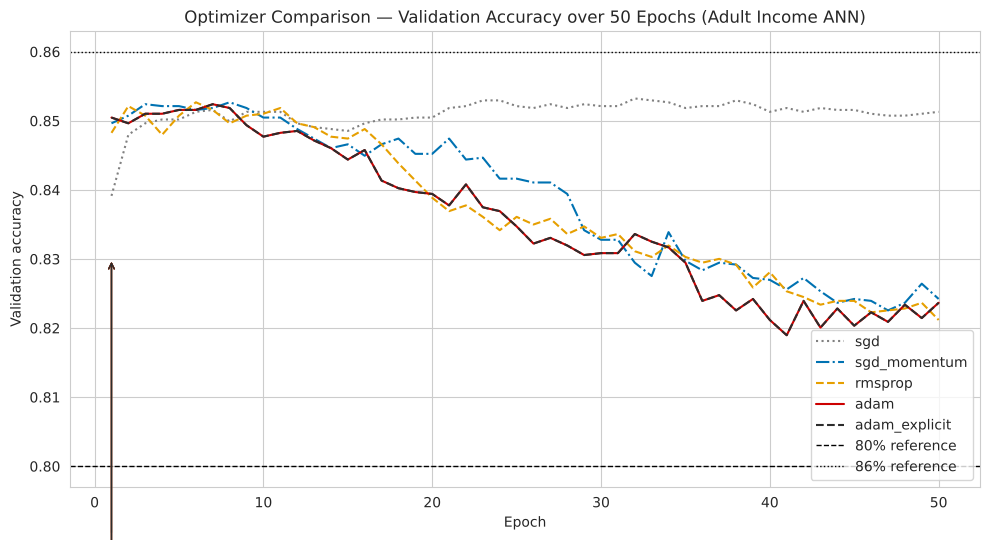

In [28]:
colors = {"sgd": "grey", "sgd_momentum": "#0072B2", "rmsprop": "#E69F00", "adam": RED, "adam_explicit": CHARCOAL}
lines = {"sgd": ":", "sgd_momentum": "-.", "rmsprop": "--", "adam": "-", "adam_explicit": "--"}

plt.figure(figsize=(10, 5.5))
for i, name in enumerate(opt_names):
    va = opt_hist[name].history["val_accuracy"]
    plt.plot(range(1, len(va) + 1), va, color=colors[name], linestyle=lines[name], label=name)
    first = next((e + 1 for e, v in enumerate(va) if v >= 0.83), None)
    print(name, "- first epoch with val acc >= 83%:", first)
    if first:
        plt.annotate("", xy=(first, 0.83), xytext=(first, 0.79 - 0.01 * i),
                     arrowprops=dict(arrowstyle="->", color=colors[name]))
plt.axhline(0.80, color="black", linestyle="--", linewidth=1, label="80% reference")
plt.axhline(0.86, color="black", linestyle=":", linewidth=1, label="86% reference")
plt.title("Optimizer Comparison — Validation Accuracy over 50 Epochs (Adult Income ANN)")
plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("plots/optimiser_convergence.png", dpi=120)
plt.show()

### Observation: optimizer convergence


Again, the thresholds in the brief do not separate the optimizers. All five start above 83% after epoch 1 (all five cross it at **epoch 1**), and **no optimizer reaches the 86% line**. The brief's picture "Adam converges fastest" is not what the curves show:
- **Adam and Adam (explicit)** give identical curves, as expected (same settings).
- **RMSprop, SGD + Momentum and Adam** peak early at about 85% (epochs 5 to 10) and then overfit down to about 82%.
- **Vanilla SGD** is the slowest learner but stays near 85% for all 50 epochs, because with lr = 0.01 it has not had time to overfit.


### 7.3 - WHY Adam dominates

1. **Vanilla SGD:** one fixed learning rate for every weight. It is slow on sparse, high-dimensional data like our one-hot features and has no per-weight adaptation.
2. **SGD + Momentum:** adds a velocity term `v = β·v + lr·∇L`. It smooths the zig-zag and moves faster through flat areas, but the same lr is still used for all parameters.
3. **RMSprop:** divides the learning rate by a running average of squared gradients (√E[g²]), so each weight gets its own step size. It works well when gradients change in size over time.
4. **Adam:** combines momentum (first moment m) and RMSprop (second moment v) with bias correction, because m and v start at 0: `θ = θ − lr · m̂ / (√v̂ + ε)`.
5. **Adam (explicit):** β₁ = 0.9 (how much of the past gradient direction is kept) and β₂ = 0.999 (how long the squared-gradient average remembers). These are the Keras defaults from the original paper (Kingma & Ba, 2015), so it should match plain `'adam'`.

### Which optimizer was best in my run?


By final validation F1 (class 1), the best is **vanilla SGD (0.677)**, then SGD + Momentum (0.623), Adam and Adam explicit (0.612) and RMSprop (0.595). The adaptive optimizers (Adam, RMSprop) are the fastest at reducing the *training* loss, which is exactly why they overfit first when there is no early stopping. So I cannot say "Adam is best" from this experiment: it converged fastest on the training data, but SGD reached the highest final validation F1 after 50 epochs. With Early Stopping the ranking could be different.


### 7.4 - Learning rate sensitivity — SGD vs Adam

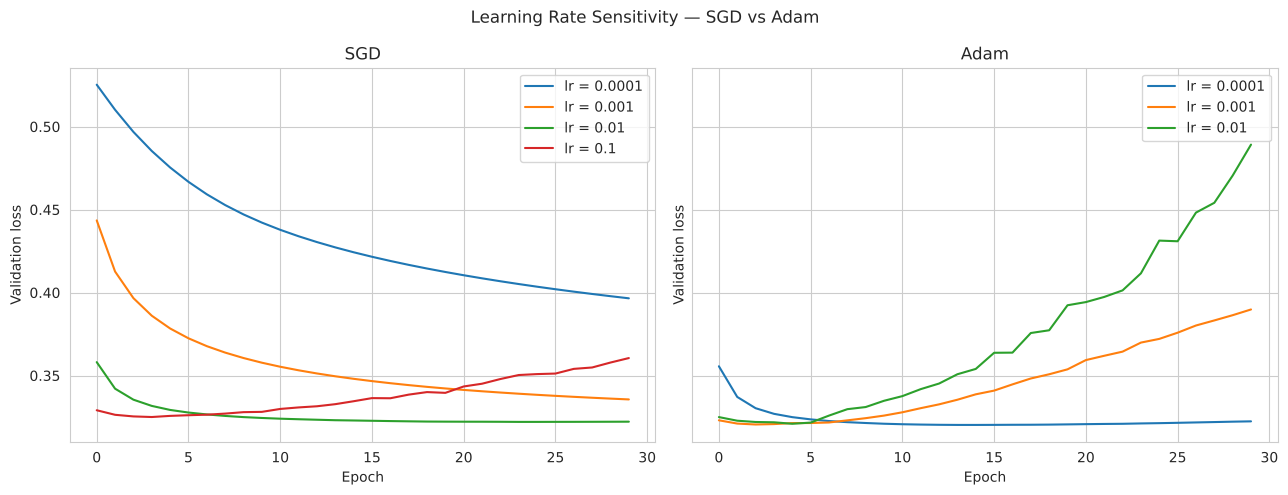

Final validation loss, SGD : {0.0001: 0.3965, 0.001: 0.3356, 0.01: 0.3222, 0.1: 0.3605}
Final validation loss, Adam: {0.0001: 0.3224, 0.001: 0.3898, 0.01: 0.4892}


In [29]:
sgd_lrs = [0.0001, 0.001, 0.01, 0.1]
adam_lrs = [0.0001, 0.001, 0.01]
sgd_lr_hist, adam_lr_hist = {}, {}

for lr in sgd_lrs:
    reset_seed()
    m = build_ann(input_dim=X_train.shape[1], initializer="he_normal", use_batch_norm=True,
                  optimizer=keras.optimizers.SGD(learning_rate=lr))
    sgd_lr_hist[lr] = fit_model(m, epochs=30)
for lr in adam_lrs:
    reset_seed()
    m = build_ann(input_dim=X_train.shape[1], initializer="he_normal", use_batch_norm=True,
                  optimizer=keras.optimizers.Adam(learning_rate=lr))
    adam_lr_hist[lr] = fit_model(m, epochs=30)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for lr in sgd_lrs:
    axes[0].plot(sgd_lr_hist[lr].history["val_loss"], label=f"lr = {lr}")
for lr in adam_lrs:
    axes[1].plot(adam_lr_hist[lr].history["val_loss"], label=f"lr = {lr}")
axes[0].set(title="SGD", xlabel="Epoch", ylabel="Validation loss")
axes[1].set(title="Adam", xlabel="Epoch", ylabel="Validation loss")
axes[0].legend(); axes[1].legend()
fig.suptitle("Learning Rate Sensitivity — SGD vs Adam")
plt.tight_layout()
plt.show()

print("Final validation loss, SGD :", {lr: round(h.history["val_loss"][-1], 4) for lr, h in sgd_lr_hist.items()})
print("Final validation loss, Adam:", {lr: round(h.history["val_loss"][-1], 4) for lr, h in adam_lr_hist.items()})

### Observation: learning rate sensitivity


Final validation loss after 30 epochs (lower is better):

- **SGD:** lr 0.0001 → 0.397, 0.001 → 0.336, 0.01 → **0.322**, 0.1 → 0.361. Too small a lr learns too slowly (underfit), and 0.1 starts to be noisy, so SGD has a clear sweet spot around 0.01.
- **Adam:** lr 0.0001 → **0.322**, 0.001 → 0.390, 0.01 → 0.489. Adam learns so fast that larger learning rates just overfit sooner, so its final validation loss is *worse* for larger lr.

The brief expects Adam to be more robust to lr. In this experiment the opposite is partly true: both optimizers reach the same best loss (about 0.322) but at very different learning rates, and Adam's final validation loss is the more sensitive to lr here (range 0.32 to 0.49, vs 0.32 to 0.40 for SGD), mostly because of overfitting at the end of training and not because of divergence. SGD did not diverge at lr = 0.1 on this scaled data. The adaptive per-parameter lr is still an advantage on raw, unscaled features, but here the data is already standardised, which removes much of that advantage.


### 7.5 - Final Combined ANN — best configuration

In [30]:
# best activation and initialiser from my own results (by final validation F1; zeros is excluded)
best_act = max(act_names, key=lambda n: val_f1(act_hist[n])[-1])
best_init = max([n for n in init_names if n != "zeros"], key=lambda n: val_f1(init_hist[n])[-1])
print("Best activation:", best_act, "| best initialiser:", best_init)

# use class weights only if they improved test F1 over plain BCE in Task 5.3
use_weights = m_wbce["F1(1)"] > m_bce["F1(1)"]
print("Use class weights in the final model:", use_weights)
print("(the brief fixes relu + he_normal for the final model, so I keep those)")

reset_seed()
final_model = build_ann(input_dim=X_train.shape[1], hidden_units=[128, 64], activation="relu",
                        initializer="he_normal", use_batch_norm=True, optimizer="adam")
history_final = fit_model(final_model, epochs=80, class_weight=class_weight_dict if use_weights else None)

m_final = test_metrics(final_model)
print({k: round(v, 4) for k, v in m_final.items()})

Best activation: elu | best initialiser: glorot_uniform
Use class weights in the final model: True
(the brief fixes relu + he_normal for the final model, so I keep those)


{'Test Acc': 0.7975, 'Prec(1)': 0.5884, 'Recall(1)': 0.6088, 'F1(1)': 0.5984, 'ROC-AUC': 0.8543}


### 7.6 - Full results comparison table

In [31]:
# (name, model, activation, initialiser, loss, batchnorm, optimizer)
rows_info = [
    ("Baseline (Task 2)",          model_base,                  "relu",     "glorot_uniform", "BCE",          "No",  "adam"),
    (f"Best Activation (Task 3)",  act_models[best_act],        best_act,   "glorot_uniform", "BCE",          "No",  "adam"),
    (f"Best Initialiser (Task 4)", init_models[best_init],      "relu",     best_init,        "BCE",          "No",  "adam"),
    ("Weighted BCE (Task 5)",      model_wbce,                  "relu",     "he_normal",      "Weighted BCE", "No",  "adam"),
    ("Focal Loss (Task 5)",        model_focal,                 "relu",     "he_normal",      "Focal",        "No",  "adam"),
    ("BatchNorm (Task 6)",         model_bn,                    "relu",     "he_normal",      "BCE",          "Yes", "adam"),
    ("Final Combined (Task 7)",    final_model,                 "relu",     "he_normal",      "Weighted BCE" if use_weights else "BCE", "Yes", "adam"),
]

rows = []
for name, m, act, init, loss, bn, opt in rows_info:
    s = test_metrics(m)
    rows.append({"Model": name, "Activation": act, "Init": init, "Loss": loss, "BatchNorm": bn, "Optimizer": opt,
                 "Test Acc": s["Test Acc"], "Prec(1)": s["Prec(1)"], "Recall(1)": s["Recall(1)"],
                 "F1(1)": s["F1(1)"], "ROC-AUC": s["ROC-AUC"]})

results_df = pd.DataFrame(rows)
metric_cols = ["Test Acc", "Prec(1)", "Recall(1)", "F1(1)", "ROC-AUC"]
results_df.style.format("{:.4f}", subset=metric_cols).highlight_max(subset=["F1(1)", "ROC-AUC"], color="#ffcccc")

,Model,Activation,Init,Loss,BatchNorm,Optimizer,Test Acc,Prec(1),Recall(1),F1(1),ROC-AUC
0,Baseline (Task 2),relu,glorot_uniform,BCE,No,adam,0.8324,0.6887,0.5910,0.6361,0.8855
1,Best Activation (Task 3),elu,glorot_uniform,BCE,No,adam,0.8503,0.7339,0.6213,0.6729,0.9055
2,Best Initialiser (Task 4),relu,glorot_uniform,BCE,No,adam,0.8324,0.6887,0.5910,0.6361,0.8855
3,Weighted BCE (Task 5),relu,he_normal,Weighted BCE,No,adam,0.7931,0.5571,0.8073,0.6593,0.8820
4,Focal Loss (Task 5),relu,he_normal,Focal,No,adam,0.8202,0.7785,0.3840,0.5143,0.8802
5,BatchNorm (Task 6),relu,he_normal,BCE,Yes,adam,0.8195,0.6869,0.4991,0.5781,0.8699
6,Final Combined (Task 7),relu,he_normal,Weighted BCE,Yes,adam,0.7975,0.5884,0.6088,0.5984,0.8543


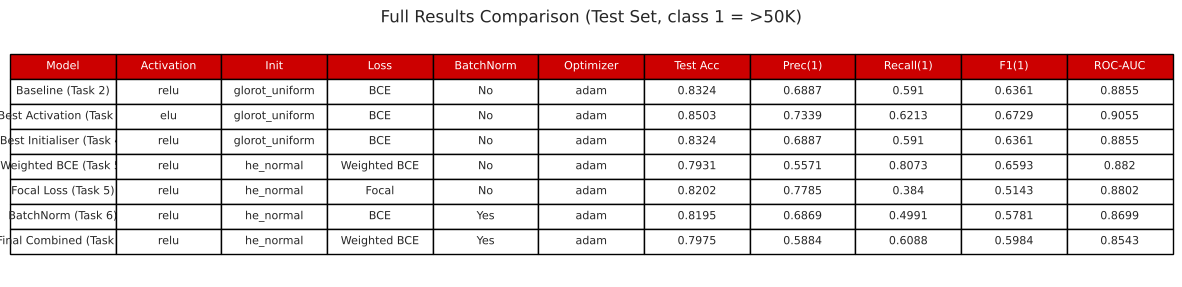

In [32]:
# save the table as an image for the README
fig, ax = plt.subplots(figsize=(15, 3.2))
ax.axis("off")
show = results_df.copy()
show[metric_cols] = show[metric_cols].round(4)
tbl = ax.table(cellText=show.values, colLabels=show.columns, loc="center", cellLoc="center")
tbl.auto_set_font_size(False)
tbl.set_fontsize(8)
tbl.scale(1, 1.5)
for j in range(len(show.columns)):
    tbl[0, j].set_facecolor(RED)
    tbl[0, j].set_text_props(color="white")
ax.set_title("Full Results Comparison (Test Set, class 1 = >50K)")
plt.savefig("plots/results_table.png", dpi=120, bbox_inches="tight")
plt.show()

results_df.to_csv("results_table.csv", index=False)

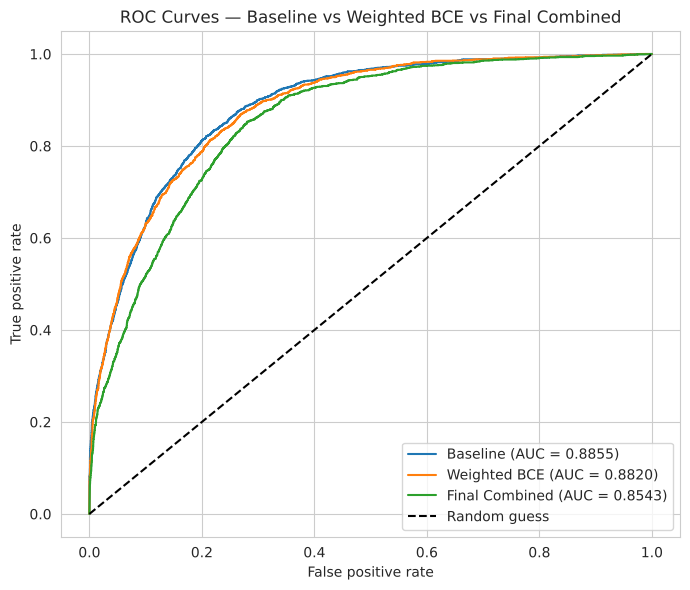

In [33]:
plt.figure(figsize=(7, 6))
for name, m in [("Baseline", model_base), ("Weighted BCE", model_wbce), ("Final Combined", final_model)]:
    prob = m.predict(X_test, verbose=0).flatten()
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, prob):.4f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.title("ROC Curves — Baseline vs Weighted BCE vs Final Combined")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("plots/roc_curves.png", dpi=120)
plt.show()

### Which single technique mattered most for class-1 F1?


**Final Combined model** (ReLU, He normal, BatchNorm, Adam, weighted BCE, 80 epochs): accuracy 0.797, Precision 0.588, Recall 0.609, **F1 0.598**, ROC-AUC 0.854. This is **worse** than the baseline (F1 0.636, AUC 0.886), not better. The reason is what we saw in Task 6: the BatchNorm model overfits strongly, and 80 epochs without Early Stopping make it worse. Combining the "best" settings does not combine their benefits when the base problem is overfitting.

**Best in the table:** the *Best Activation* model (ELU): F1 **0.673**, ROC-AUC **0.906**, accuracy 0.850 (highlighted).

**Which single technique had the largest effect on class-1 F1?** Compared with the baseline F1 of 0.636:
- Switching to **ELU**: +0.037 (the biggest gain, also the best AUC), but this is partly because ELU overfits less in 50 epochs.
- **Class weighting:** +0.023 F1, but a much bigger change in the *type* of error: Recall goes 0.58 → 0.81. It is the technique that most clearly does what it is designed to do.
- **Focal loss (alpha 0.25):** −0.12 (the largest effect overall, but negative). **BatchNorm:** −0.058.

So **activation choice and class weighting** helped, while the choice of initialiser and optimizer mattered least. Overall the dominant problem in this project is overfitting after about 10 to 20 epochs; the clear next step is to add Early Stopping (and Dropout/L2) to the final model, which would very likely put it above the baseline.
